In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the practice dataset
df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 1. What Is an Outlier?

An outlier is a data point that differs significantly from most other observations in a dataset. Outliers can affect statistical calculations, data visualization, and machine learning models.

For example, if most restaurant bills are between 10 and 50 but one bill is 200, that value may be an outlier. However, it should be investigated before deciding whether it is incorrect or unusual but valid.

## 2. Why Do Outliers Occur?

Outliers may occur due to:

1. **Data-entry errors:** Incorrect values entered into the dataset.
2. **Measurement errors:** Inaccurate readings from instruments.
3. **Natural variation:** Genuine differences between observations.
4. **Rare events:** Unusual but valid situations.
5. **Data-processing errors:** Mistakes during calculations or data transformations.

Understanding the cause of an outlier helps us decide whether to correct, remove, transform, or retain it.

## 3. Types of Outliers

Outliers can be classified into three main types:

1. **Global Outliers:** A data point that is significantly different from the overall dataset. For example, a restaurant bill that is much higher than most other bills.

2. **Contextual Outliers:** A data point that is unusual in a specific context. For example, a high restaurant bill may be normal for a large group but unusual for one person.

3. **Collective Outliers:** A group of data points that are unusual when considered together, even if individual points appear normal.

Understanding these types helps select an appropriate outlier detection technique.

In [2]:
# Select the numerical column
column = "total_bill"

# Calculate Q1, Q3, and IQR
Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)
IQR = Q3 - Q1

# Calculate the lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df[column] < lower_bound) |
    (df[column] > upper_bound)
]

print("Column:", column)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

display(outliers)

Column: total_bill
Q1: 13.3475
Q3: 24.127499999999998
IQR: 10.779999999999998
Lower bound: -2.8224999999999945
Upper bound: 40.29749999999999
Number of outliers: 9


,total_bill,tip,sex,smoker,day,time,size
59,48.27,6.73,Male,No,Sat,Dinner,4
102,44.30,2.50,Female,Yes,Sat,Dinner,3
142,41.19,5.00,Male,No,Thur,Lunch,5
156,48.17,5.00,Male,No,Sun,Dinner,6
170,50.81,10.00,Male,Yes,Sat,Dinner,3
182,45.35,3.50,Male,Yes,Sun,Dinner,3
184,40.55,3.00,Male,Yes,Sun,Dinner,2
197,43.11,5.00,Female,Yes,Thur,Lunch,4
212,48.33,9.00,Male,No,Sat,Dinner,4


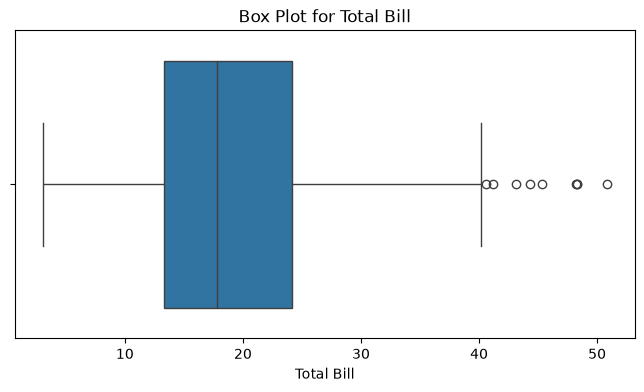

In [3]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["total_bill"])
plt.title("Box Plot for Total Bill")
plt.xlabel("Total Bill")
plt.show()

In [4]:
from scipy.stats import zscore

# Calculate Z-scores for total_bill
df["z_score"] = zscore(df["total_bill"])

# Identify potential outliers
zscore_outliers = df[df["z_score"].abs() > 3]

print("Number of Z-score outliers:", len(zscore_outliers))
display(zscore_outliers)

Number of Z-score outliers: 4


,total_bill,tip,sex,smoker,day,time,size,z_score
59,48.27,6.73,Male,No,Sat,Dinner,4,3.206166
156,48.17,5.00,Male,No,Sun,Dinner,6,3.194910
170,50.81,10.00,Male,Yes,Sat,Dinner,3,3.492068
212,48.33,9.00,Male,No,Sat,Dinner,4,3.212919


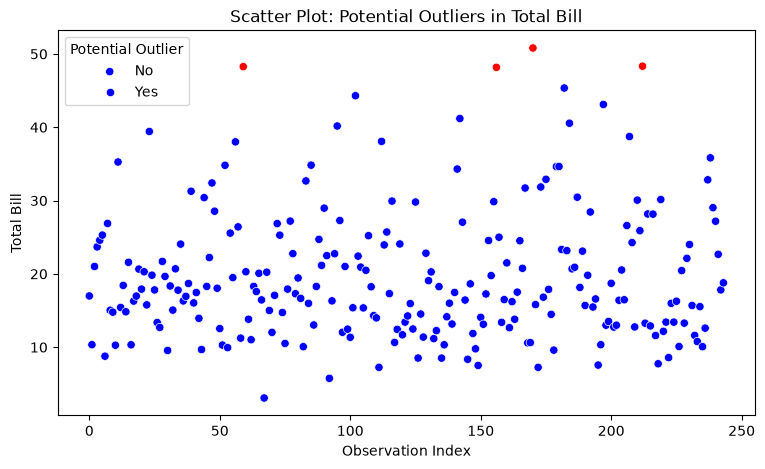

In [5]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x=df.index,
    y="total_bill",
    hue=df["z_score"].abs() > 3,
    palette={True: "red", False: "blue"}
)

plt.title("Scatter Plot: Potential Outliers in Total Bill")
plt.xlabel("Observation Index")
plt.ylabel("Total Bill")
plt.legend(title="Potential Outlier", labels=["No", "Yes"])
plt.show()

In [6]:
print("Outlier Detection Comparison")
print("----------------------------")
print("IQR method:", len(outliers), "potential outliers")
print("Z-score method:", len(zscore_outliers), "potential outliers")

Outlier Detection Comparison
----------------------------
IQR method: 9 potential outliers
Z-score method: 4 potential outliers


## 4. Outlier Investigation and Decisions

Outliers identified by the IQR and Z-score methods were treated as potential outliers requiring further investigation. Each observation should be checked for data-entry errors and measurement issues.

- **Remove:** Only when the value is confirmed to be erroneous and cannot be corrected reliably.
- **Transform:** When the distribution is highly skewed and a transformation is appropriate for the analysis.
- **Retain:** When the observation is unusual but valid and represents genuine variation.

Outliers should not be removed automatically. The reason for each decision must be documented.

In [7]:
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2

# Select two numerical variables
data = df[["total_bill", "tip"]].dropna()

# Calculate mean and covariance
mean_vector = data.mean().values
cov_matrix = data.cov().values
inverse_cov = np.linalg.pinv(cov_matrix)

# Calculate Mahalanobis distance for each observation
distances = data.apply(
    lambda row: mahalanobis(
        row.values, mean_vector, inverse_cov
    ),
    axis=1
)

# Flag potential multivariate outliers
threshold = np.sqrt(chi2.ppf(0.99, df=2))
multivariate_outliers = data[distances > threshold]

print("Mahalanobis distance threshold:", round(threshold, 2))
print("Potential multivariate outliers:", len(multivariate_outliers))

display(multivariate_outliers)

Mahalanobis distance threshold: 3.03
Potential multivariate outliers: 11


,total_bill,tip
23,39.42,7.58
59,48.27,6.73
102,44.30,2.50
156,48.17,5.00
170,50.81,10.00
172,7.25,5.15
182,45.35,3.50
183,23.17,6.50
184,40.55,3.00
212,48.33,9.00


In [8]:
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2

# Select two numerical variables
data = df[["total_bill", "tip"]].dropna()

# Calculate mean and covariance
mean_vector = data.mean().values
cov_matrix = data.cov().values
inverse_cov = np.linalg.pinv(cov_matrix)

# Calculate Mahalanobis distance for each observation
distances = data.apply(
    lambda row: mahalanobis(
        row.values, mean_vector, inverse_cov
    ),
    axis=1
)

# Flag potential multivariate outliers
threshold = np.sqrt(chi2.ppf(0.99, df=2))
multivariate_outliers = data[distances > threshold]

print("Mahalanobis distance threshold:", round(threshold, 2))
print("Potential multivariate outliers:", len(multivariate_outliers))

display(multivariate_outliers)

Mahalanobis distance threshold: 3.03
Potential multivariate outliers: 11


,total_bill,tip
23,39.42,7.58
59,48.27,6.73
102,44.30,2.50
156,48.17,5.00
170,50.81,10.00
172,7.25,5.15
182,45.35,3.50
183,23.17,6.50
184,40.55,3.00
212,48.33,9.00


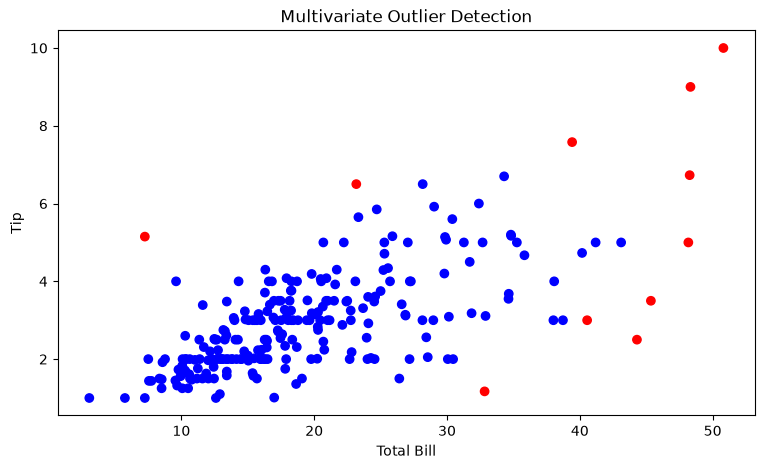

In [9]:
plt.figure(figsize=(9, 5))

plt.scatter(
    data["total_bill"],
    data["tip"],
    c=np.where(distances > threshold, "red", "blue")
)

plt.title("Multivariate Outlier Detection")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.show()

## Conclusion

In this notebook, I studied outliers and their causes, including data-entry errors, measurement errors, natural variation, and rare events. I applied the IQR method and Z-score method to detect univariate outliers, visualized potential outliers using box plots and scatter plots, and explored multivariate outlier detection using Mahalanobis distance.

The results from different methods may vary because each method uses different assumptions and thresholds. Identified outliers should be investigated to determine whether they are errors or unusual but valid observations. Outliers should not be automatically removed; any removal, transformation, or retention decision must be justified and documented.